In [1]:
!pip install -q wfdb imbalanced-learn

import os, time
import numpy as np
import matplotlib.pyplot as plt
import wfdb
from scipy.signal import butter, filtfilt
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.utils.class_weight import compute_class_weight

np.random.seed(42)
tf.random.set_seed(42)
FS = 360
print(tf.__version__, tf.config.list_physical_devices('GPU'))

2.21.0 [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import drive
drive.mount('/content/drive')

BASE = '/content/drive/MyDrive/ecg_project'
os.makedirs(BASE, exist_ok=True)

Mounted at /content/drive


In [3]:
DATA = '/content/mitdb'
if not os.path.exists(DATA):
    wfdb.dl_database('mitdb', DATA)
print(len(os.listdir(DATA)), 'files')

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

KeyboardInterrupt: 

In [4]:
!rm -rf /content/mitdb

In [5]:
!curl -I -m 20 https://physionet.org/files/mitdb/1.0.0/100.hea

HTTP/2 200 
server: nginx/1.22.1
date: Sat, 24 Oct 2026 11:03:50 GMT
content-type: text/plain; charset=utf-8
content-length: 143
last-modified: Thu, 30 Jul 1992 05:36:18 GMT
content-disposition: inline; filename=100.hea
etag: "2a777fd2-8f"
content-security-policy: sandbox; default-src 'self'
accept-ranges: bytes



In [6]:
!rm -rf /content/mitdb /content/mit-bih-arrhythmia-database-1.0.0
!wget -q --timeout=60 -O /content/mitdb.zip https://physionet.org/static/published-projects/mitdb/mit-bih-arrhythmia-database-1.0.0.zip
!ls -lh /content/mitdb.zip


^C
-rw-r--r-- 1 root root 2.3M Oct 24 11:10 /content/mitdb.zip


In [7]:
import requests
from concurrent.futures import ThreadPoolExecutor, as_completed

DATA = '/content/mitdb'
os.makedirs(DATA, exist_ok=True)

DS1 = [101,106,108,109,112,114,115,116,118,119,122,124,201,203,205,207,208,209,215,220,223,230]
DS2 = [100,103,105,111,113,117,121,123,200,202,210,212,213,214,219,221,222,228,231,232,233,234]
records = DS1 + DS2
base = 'https://physionet.org/files/mitdb/1.0.0/'

def get(fname):
    path = f'{DATA}/{fname}'
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return fname, True
    for _ in range(3):
        try:
            r = requests.get(base + fname, timeout=30)
            if r.status_code == 200:
                with open(path, 'wb') as f:
                    f.write(r.content)
                return fname, True
        except Exception:
            pass
    return fname, False

files = [f'{r}.{e}' for r in records for e in ('dat', 'hea', 'atr')]
done, failed = 0, []
with ThreadPoolExecutor(8) as ex:
    for fut in as_completed([ex.submit(get, f) for f in files]):
        name, ok = fut.result()
        done += 1
        if not ok:
            failed.append(name)
        if done % 20 == 0:
            print(done, '/', len(files))

print('total', len(files), '| failed:', failed)

KeyboardInterrupt: 

In [8]:
import os, time, requests

d = '/content/mitdb'
n = len(os.listdir(d)) if os.path.exists(d) else 0
mb = sum(os.path.getsize(f'{d}/{f}') for f in os.listdir(d)) / 1e6 if n else 0
print('abhi tak aayi hui files:', n, '|', round(mb, 1), 'MB')

t = time.time()
r = requests.get('https://physionet.org/files/mitdb/1.0.0/100.dat', stream=True, timeout=30)
got = 0
for chunk in r.iter_content(65536):
    got += len(chunk)
    if time.time() - t > 20:
        break
sec = time.time() - t
print(round(got / 1e3), 'KB in', round(sec, 1), 's ->', round(got / 1e3 / sec), 'KB/s')

abhi tak aayi hui files: 20 | 3.9 MB
131 KB in 25.0 s -> 5 KB/s


In [9]:
import time, requests

url = 'https://physionet-open.s3.amazonaws.com/mitdb/1.0.0/100.dat'
t = time.time()
r = requests.get(url, stream=True, timeout=30)
print('status:', r.status_code)
got = 0
for chunk in r.iter_content(65536):
    got += len(chunk)
    if time.time() - t > 15:
        break
sec = time.time() - t
print(round(got / 1e3), 'KB in', round(sec, 1), 's ->', round(got / 1e3 / sec), 'KB/s')

status: 200
1950 KB in 0.6 s -> 3183 KB/s


In [10]:
import os, requests
from concurrent.futures import ThreadPoolExecutor, as_completed

DATA = '/content/mitdb'
os.makedirs(DATA, exist_ok=True)

DS1 = [101,106,108,109,112,114,115,116,118,119,122,124,201,203,205,207,208,209,215,220,223,230]
DS2 = [100,103,105,111,113,117,121,123,200,202,210,212,213,214,219,221,222,228,231,232,233,234]
base = 'https://physionet-open.s3.amazonaws.com/mitdb/1.0.0/'

def get(fname):
    path = f'{DATA}/{fname}'
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return fname, True
    for _ in range(3):
        try:
            r = requests.get(base + fname, timeout=60)
            if r.status_code == 200:
                open(path, 'wb').write(r.content)
                return fname, True
        except Exception:
            pass
    return fname, False

files = [f'{r}.{e}' for r in DS1 + DS2 for e in ('dat', 'hea', 'atr')]
failed = []
with ThreadPoolExecutor(8) as ex:
    for i, fut in enumerate(as_completed([ex.submit(get, f) for f in files]), 1):
        name, ok = fut.result()
        if not ok:
            failed.append(name)
        if i % 20 == 0:
            print(i, '/', len(files))
print('failed:', failed)
print(len(os.listdir(DATA)), 'files in', DATA)

20 / 132
40 / 132
60 / 132
80 / 132
100 / 132
120 / 132
failed: []
132 files in /content/mitdb


['MLII', 'V5'] 360


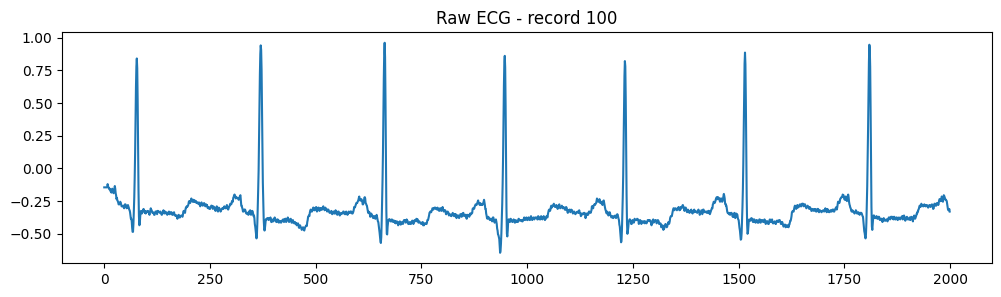

['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


In [11]:
record = wfdb.rdrecord(f'{DATA}/100')
ann = wfdb.rdann(f'{DATA}/100', 'atr')
print(record.sig_name, record.fs)
sig = record.p_signal[:, 0]

plt.figure(figsize=(12, 3))
plt.plot(sig[:2000])
plt.title('Raw ECG - record 100')
plt.show()
print(ann.symbol[:20])

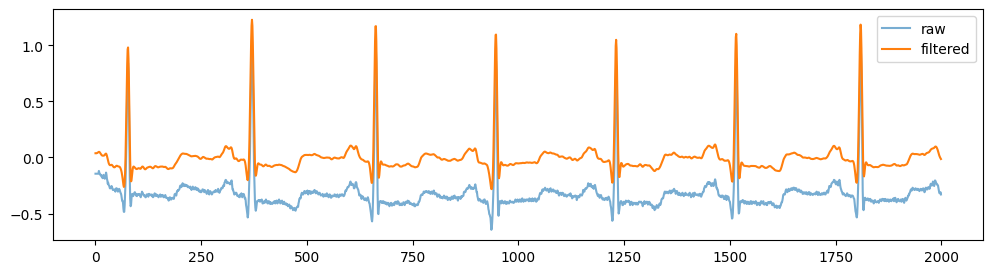

In [12]:
def bandpass(x, low=0.5, high=40, fs=FS):
    b, a = butter(3, [low, high], btype='band', fs=fs)
    return filtfilt(b, a, x)

clean = bandpass(sig)
plt.figure(figsize=(12, 3))
plt.plot(sig[:2000], label='raw', alpha=0.6)
plt.plot(clean[:2000], label='filtered')
plt.legend(); plt.show()

In [13]:
AAMI = {}
for s in ['N', 'L', 'R', 'e', 'j']: AAMI[s] = 0   # Normal
for s in ['A', 'a', 'J', 'S']:      AAMI[s] = 1   # Supraventricular
for s in ['V', 'E']:                AAMI[s] = 2   # Ventricular
AAMI['F'] = 3                                      # Fusion
for s in ['/', 'f', 'Q']:           AAMI[s] = 4   # Unknown

def process_record(rec_id, pre=90, post=110):
    rec = wfdb.rdrecord(f'{DATA}/{rec_id}')
    ann = wfdb.rdann(f'{DATA}/{rec_id}', 'atr')
    lead = rec.sig_name.index('MLII') if 'MLII' in rec.sig_name else 0
    sig = bandpass(rec.p_signal[:, lead])

    peaks = [(s, AAMI[sym]) for s, sym in zip(ann.sample, ann.symbol) if sym in AAMI]
    X, y, rr = [], [], []
    for i, (idx, label) in enumerate(peaks):
        if idx - pre < 0 or idx + post > len(sig):
            continue
        prev_rr = (idx - peaks[i-1][0]) / FS if i > 0 else np.nan
        next_rr = (peaks[i+1][0] - idx) / FS if i < len(peaks) - 1 else np.nan
        beat = sig[idx - pre: idx + post]
        beat = (beat - beat.mean()) / (beat.std() + 1e-8)
        X.append(beat); y.append(label); rr.append([prev_rr, next_rr])

    rr = np.array(rr, dtype=float)
    rr = np.where(np.isnan(rr), np.nanmean(rr, axis=0), rr)
    return np.array(X), np.array(y), rr

Xt, yt, rrt = process_record('100')
print(Xt.shape, np.bincount(yt, minlength=5))

(2271, 200) [2237   33    1    0    0]


In [14]:
DS1 = [101,106,108,109,112,114,115,116,118,119,122,124,201,203,205,207,208,209,215,220,223,230]
DS2 = [100,103,105,111,113,117,121,123,200,202,210,212,213,214,219,221,222,228,231,232,233,234]
VAL = [106, 124, 205, 209, 223]
TRAIN = [r for r in DS1 if r not in VAL]

def build(records):
    Xs, ys, rrs = [], [], []
    for r in records:
        X, y, rr = process_record(str(r))
        Xs.append(X); ys.append(y); rrs.append(rr)
    return np.vstack(Xs), np.concatenate(ys), np.vstack(rrs)

X_train, y_train, rr_train = build(TRAIN)
X_val,   y_val,   rr_val   = build(VAL)
X_test,  y_test,  rr_test  = build(DS2)

for name, arr in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(name, len(arr), np.bincount(arr, minlength=5))

for n, a in dict(X_train=X_train, y_train=y_train, rr_train=rr_train,
                 X_val=X_val, y_val=y_val, rr_val=rr_val,
                 X_test=X_test, y_test=y_test, rr_test=rr_test).items():
    np.save(f'{BASE}/{n}.npy', a)
print('saved to', BASE)

train 39096 [35574   454  2676   384     8]
val 11912 [10280   490  1112    30     0]
test 49697 [44245  1837  3220   388     7]
saved to /content/drive/MyDrive/ecg_project


In [15]:
classes = np.unique(y_train)
w = compute_class_weight('balanced', classes=classes, y=y_train)
class_weight = {int(c): float(np.sqrt(wi)) for c, wi in zip(classes, w)}
print(class_weight)

def macro_f1_4(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=[0, 1, 2, 3], average='macro', zero_division=0)

def sparse_focal_loss(gamma=2.0):
    def loss(y_true, y_pred):
        y_true = tf.cast(tf.reshape(y_true, [-1]), tf.int32)
        oh = tf.one_hot(y_true, depth=5)
        y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0)
        return tf.reduce_sum(tf.pow(1 - y_pred, gamma) * (-oh * tf.math.log(y_pred)), axis=-1)
    return loss

{0: 0.46882937007245684, 1: 4.150049094768252, 2: 1.709377984581059, 3: 4.512482686947397, 4: 31.263397128271265}


In [16]:
from sklearn.ensemble import RandomForestClassifier

Xb_train = np.hstack([X_train, rr_train])
Xb_test  = np.hstack([X_test, rr_test])

rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', n_jobs=-1, random_state=42)
rf.fit(Xb_train, y_train)
pred_rf = rf.predict(Xb_test)

print(classification_report(y_test, pred_rf, labels=[0,1,2,3,4],
                            target_names=['N','S','V','F','Q'], digits=3, zero_division=0))
print('Macro-F1 (N,S,V,F):', round(macro_f1_4(y_test, pred_rf), 4))

              precision    recall  f1-score   support

           N      0.934     0.997     0.964     44245
           S      0.553     0.011     0.022      1837
           V      0.981     0.709     0.823      3220
           F      0.000     0.000     0.000       388
           Q      0.000     0.000     0.000         7

    accuracy                          0.934     49697
   macro avg      0.494     0.343     0.362     49697
weighted avg      0.915     0.934     0.913     49697

Macro-F1 (N,S,V,F): 0.4525


In [17]:
class_weight = {k: min(v, 10.0) for k, v in class_weight.items()}
print(class_weight)

{0: 0.46882937007245684, 1: 4.150049094768252, 2: 1.709377984581059, 3: 4.512482686947397, 4: 10.0}


In [18]:
def build_cnn():
    return models.Sequential([
        layers.Input((200, 1)),
        layers.Conv1D(32, 5, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling1D(2),
        layers.Conv1D(64, 5, padding='same', activation='relu'), layers.BatchNormalization(), layers.MaxPooling1D(2),
        layers.Conv1D(128, 3, padding='same', activation='relu'), layers.GlobalAveragePooling1D(),
        layers.Dense(64, activation='relu'), layers.Dropout(0.4),
        layers.Dense(5, activation='softmax')])

cbs = [callbacks.EarlyStopping(patience=5, restore_best_weights=True),
       callbacks.ReduceLROnPlateau(patience=2, factor=0.5)]

cnn = build_cnn()
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist = cnn.fit(X_train[..., None], y_train,
               validation_data=(X_val[..., None], y_val),
               epochs=30, batch_size=256,
               class_weight=class_weight, callbacks=cbs)
cnn.save(f'{BASE}/cnn_model.keras')

pred_cnn = np.argmax(cnn.predict(X_test[..., None]), axis=1)
print(classification_report(y_test, pred_cnn, labels=[0,1,2,3,4],
                            target_names=['N','S','V','F','Q'], digits=3, zero_division=0))
print('Macro-F1 (N,S,V,F):', round(macro_f1_4(y_test, pred_cnn), 4))

Epoch 1/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 26s 74ms/step - accuracy: 0.9192 - loss: 0.4310 - val_accuracy: 0.6678 - val_loss: 1.1397 - learning_rate: 0.0010
Epoch 2/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9471 - loss: 0.2999 - val_accuracy: 0.8983 - val_loss: 0.5249 - learning_rate: 0.0010
Epoch 3/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9566 - loss: 0.2375 - val_accuracy: 0.9281 - val_loss: 0.3278 - learning_rate: 0.0010
Epoch 4/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9634 - loss: 0.1849 - val_accuracy: 0.9180 - val_loss: 0.2740 - learning_rate: 0.0010
Epoch 5/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9677 - loss: 0.1600 - val_accuracy: 0.9236 - val_loss: 0.2892 - learning_rate: 0.0010
Epoch 6/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9700 - loss: 0.1448 - val_accuracy: 0.9219 - val_loss: 0.3012 - learning_rate: 0.0010
Epoch 7/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9763 - loss: 0.1219 

In [19]:
def add_feats(rr):
    prev, nxt = rr[:, 0], rr[:, 1]
    loc = np.array([prev[max(0, i-10):i+1].mean() for i in range(len(prev))])
    return np.column_stack([prev, nxt, prev / (nxt + 1e-6), prev / (loc + 1e-6), nxt / (loc + 1e-6)])

def build2(records):
    Xs, ys, fs = [], [], []
    for r in records:
        X, y, rr = process_record(str(r))
        Xs.append(X); ys.append(y); fs.append(add_feats(rr))
    return np.vstack(Xs), np.concatenate(ys), np.vstack(fs)

X_train, y_train, f_train = build2(TRAIN)
X_val,   y_val,   f_val   = build2(VAL)
X_test,  y_test,  f_test  = build2(DS2)

f_train, f_val, f_test = [np.clip(f, 0, 5) for f in (f_train, f_val, f_test)]
mu, sd = f_train.mean(0), f_train.std(0) + 1e-8
f_train, f_val, f_test = [(f - mu) / sd for f in (f_train, f_val, f_test)]
print(f_train.shape, f_val.shape, f_test.shape)

(39096, 5) (11912, 5) (49697, 5)


In [20]:
rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', n_jobs=-1, random_state=42)
rf.fit(np.hstack([X_train, f_train]), y_train)
pred_rf = rf.predict(np.hstack([X_test, f_test]))
print(classification_report(y_test, pred_rf, labels=[0,1,2,3,4],
                            target_names=['N','S','V','F','Q'], digits=3, zero_division=0))
print('RF Macro-F1 (N,S,V,F):', round(macro_f1_4(y_test, pred_rf), 4))

              precision    recall  f1-score   support

           N      0.939     0.996     0.967     44245
           S      0.788     0.014     0.028      1837
           V      0.982     0.783     0.871      3220
           F      0.000     0.000     0.000       388
           Q      0.000     0.000     0.000         7

    accuracy                          0.938     49697
   macro avg      0.542     0.359     0.373     49697
weighted avg      0.928     0.938     0.918     49697

RF Macro-F1 (N,S,V,F): 0.4664


In [21]:
def build_cnn2():
    b_in = layers.Input((200, 1))
    x = layers.Conv1D(32, 5, padding='same', activation='relu')(b_in)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 5, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(128, 3, padding='same', activation='relu')(x)
    x = layers.GlobalAveragePooling1D()(x)

    r_in = layers.Input((5,))
    r = layers.Dense(32, activation='relu')(r_in)

    z = layers.Concatenate()([x, r])
    z = layers.Dense(64, activation='relu')(z)
    z = layers.Dropout(0.4)(z)
    out = layers.Dense(5, activation='softmax')(z)
    return models.Model([b_in, r_in], out)

cnn2 = build_cnn2()
cnn2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
cnn2.fit([X_train[..., None], f_train], y_train,
         validation_data=([X_val[..., None], f_val], y_val),
         epochs=30, batch_size=256,
         class_weight=class_weight, callbacks=cbs)
cnn2.save(f'{BASE}/cnn_rr_model.keras')

pred2 = np.argmax(cnn2.predict([X_test[..., None], f_test]), axis=1)
print(classification_report(y_test, pred2, labels=[0,1,2,3,4],
                            target_names=['N','S','V','F','Q'], digits=3, zero_division=0))
print('CNN+RR Macro-F1 (N,S,V,F):', round(macro_f1_4(y_test, pred2), 4))

Epoch 1/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 11s 36ms/step - accuracy: 0.9324 - loss: 0.3574 - val_accuracy: 0.7428 - val_loss: 0.9598 - learning_rate: 0.0010
Epoch 2/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9629 - loss: 0.1770 - val_accuracy: 0.8541 - val_loss: 0.6636 - learning_rate: 0.0010
Epoch 3/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.9743 - loss: 0.1252 - val_accuracy: 0.9303 - val_loss: 0.3773 - learning_rate: 5.0000e-04
Epoch 4/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9784 - loss: 0.1081 - val_accuracy: 0.9645 - val_loss: 0.1587 - learning_rate: 5.0000e-04
Epoch 5/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9809 - loss: 0.0941 - val_accuracy: 0.9605 - val_loss: 0.1364 - learning_rate: 5.0000e-04
Epoch 6/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.9820 - loss: 0.0844 - val_accuracy: 0.9569 - val_loss: 0.1452 - learning_rate: 5.0000e-04
Epoch 7/30
153/153 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.982

In [22]:
def run_exp(name, loss='sparse_categorical_crossentropy', cw=None,
            Xtr=X_train, ftr=f_train, ytr=y_train, seed=42):
    tf.keras.utils.set_random_seed(seed)
    m = build_cnn2()
    m.compile(optimizer='adam', loss=loss, metrics=['accuracy'])
    m.fit([Xtr[..., None], ftr], ytr,
          validation_data=([X_val[..., None], f_val], y_val),
          epochs=30, batch_size=256, class_weight=cw, verbose=0,
          callbacks=[callbacks.EarlyStopping(patience=5, restore_best_weights=True),
                     callbacks.ReduceLROnPlateau(patience=2, factor=0.5)])
    p = np.argmax(m.predict([X_test[..., None], f_test], verbose=0), axis=1)
    f1s = f1_score(y_test, p, labels=[0, 1, 2, 3], average=None, zero_division=0)
    print(f'{name} | macro-F1: {f1s.mean():.4f} | F1 (N,S,V,F): {np.round(f1s, 3)}')
    return m, p

# 1) full balanced weights (Q ko cap kar rahe hain)
cw_full = {int(c): min(float(wi), 20.0) for c, wi in zip(classes, w)}
m_full, p_full = run_exp('full-weights', cw=cw_full)

# 2) focal loss (class weight ke bina)
m_focal, p_focal = run_exp('focal-loss', loss=sparse_focal_loss(2.0))

# 3) oversampling S aur F (sirf train pe, test pe kabhi nahi)
rng = np.random.default_rng(42)
def oversample(X, f, y, mult={1: 5, 3: 10}):
    Xs, fs, ys = [X], [f], [y]
    for c, k in mult.items():
        idx = np.where(y == c)[0]
        for _ in range(k):
            Xa = np.stack([np.roll(x, rng.integers(-4, 5)) for x in X[idx]])
            Xa = Xa + rng.normal(0, 0.03, Xa.shape)
            Xs.append(Xa); fs.append(f[idx]); ys.append(y[idx])
    return np.vstack(Xs), np.vstack(fs), np.concatenate(ys)

X_os, f_os, y_os = oversample(X_train, f_train, y_train)
print('oversampled train:', np.bincount(y_os, minlength=5))
m_os, p_os = run_exp('oversample', Xtr=X_os, ftr=f_os, ytr=y_os)

full-weights | macro-F1: 0.5565 | F1 (N,S,V,F): [0.943 0.389 0.891 0.003]
focal-loss | macro-F1: 0.5179 | F1 (N,S,V,F): [0.976 0.213 0.882 0.   ]
oversampled train: [35574  2724  2676  4224     8]
oversample | macro-F1: 0.5348 | F1 (N,S,V,F): [0.968 0.238 0.924 0.009]


In [24]:
def build_cnn_lstm2():
    b_in = layers.Input((200, 1))
    x = layers.Conv1D(32, 5, padding='same', activation='relu')(b_in)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
    x = layers.Conv1D(64, 5, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x); x = layers.MaxPooling1D(2)(x)
    x = layers.Bidirectional(layers.LSTM(64))(x)

    r_in = layers.Input((5,))
    r = layers.Dense(32, activation='relu')(r_in)

    z = layers.Concatenate()([x, r])
    z = layers.Dense(64, activation='relu')(z)
    z = layers.Dropout(0.4)(z)
    out = layers.Dense(5, activation='softmax')(z)
    return models.Model([b_in, r_in], out)

def run_seed(builder, seed, cw):
    tf.keras.utils.set_random_seed(seed)
    m = builder()
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    m.fit([X_train[..., None], f_train], y_train,
          validation_data=([X_val[..., None], f_val], y_val),
          epochs=30, batch_size=256, class_weight=cw, verbose=0,
          callbacks=[callbacks.EarlyStopping(patience=5, restore_best_weights=True),
                     callbacks.ReduceLROnPlateau(patience=2, factor=0.5)])
    p = np.argmax(m.predict([X_test[..., None], f_test], verbose=0), axis=1)
    f1s = f1_score(y_test, p, labels=[0, 1, 2, 3], average=None, zero_division=0)
    return m, p, f1s

results = {}
for name, builder in [('CNN+RR', build_cnn2), ('CNN-LSTM+RR', build_cnn_lstm2)]:
    runs = []
    for seed in [1, 2, 3]:
        m, p, f1s = run_seed(builder, seed, cw_full)
        runs.append((m, p, f1s))
        print(f'{name} seed {seed} | macro-F1: {f1s.mean():.4f} | {np.round(f1s, 3)}')
    results[name] = runs
    ms = np.array([r[2].mean() for r in runs])
    print(f'>>> {name}: mean {ms.mean():.4f} +/- {ms.std():.4f}\n')

CNN+RR seed 1 | macro-F1: 0.5896 | [0.963 0.449 0.906 0.04 ]
CNN+RR seed 2 | macro-F1: 0.6096 | [0.957 0.557 0.918 0.007]
CNN+RR seed 3 | macro-F1: 0.6052 | [0.965 0.554 0.896 0.006]
>>> CNN+RR: mean 0.6015 +/- 0.0086

CNN-LSTM+RR seed 1 | macro-F1: 0.4517 | [0.889 0.117 0.773 0.029]
CNN-LSTM+RR seed 2 | macro-F1: 0.4302 | [0.826 0.233 0.66  0.002]
CNN-LSTM+RR seed 3 | macro-F1: 0.4803 | [0.889 0.231 0.793 0.009]
>>> CNN-LSTM+RR: mean 0.4541 +/- 0.0205



              precision    recall  f1-score   support

           N      0.980     0.935     0.957     44245
           S      0.463     0.698     0.557      1837
           V      0.927     0.909     0.918      3220
           F      0.004     0.015     0.007       388
           Q      0.000     0.000     0.000         7

    accuracy                          0.918     49697
   macro avg      0.475     0.512     0.488     49697
weighted avg      0.949     0.918     0.932     49697



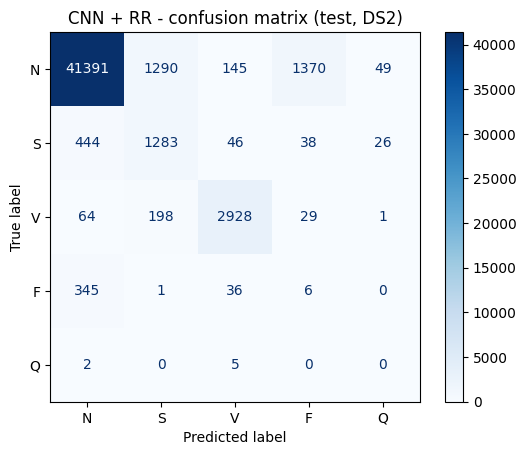

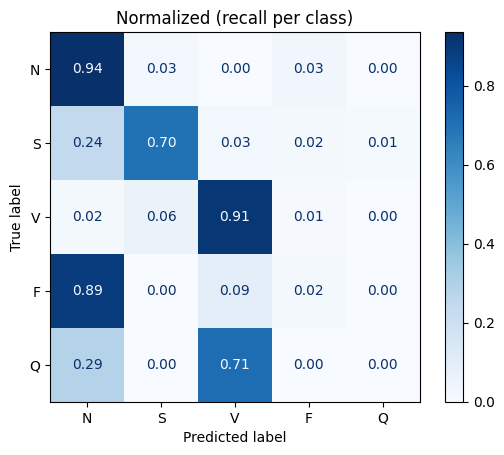

In [25]:
def val_f1(m):
    p = np.argmax(m.predict([X_val[..., None], f_val], verbose=0), axis=1)
    return f1_score(y_val, p, labels=[0, 1, 2, 3], average='macro', zero_division=0)

best_m, best_p, _ = max(results['CNN+RR'], key=lambda r: val_f1(r[0]))

names = ['N', 'S', 'V', 'F', 'Q']
print(classification_report(y_test, best_p, labels=[0,1,2,3,4], target_names=names,
                            digits=3, zero_division=0))

cm = confusion_matrix(y_test, best_p, labels=range(5))
ConfusionMatrixDisplay(cm, display_labels=names).plot(cmap='Blues', values_format='d')
plt.title('CNN + RR - confusion matrix (test, DS2)')
plt.savefig(f'{BASE}/cm_cnn_rr.png', dpi=150); plt.show()

# normalized (row-wise) version, report me ye zyada samajh aata hai
cmn = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
ConfusionMatrixDisplay(cmn, display_labels=names).plot(cmap='Blues', values_format='.2f')
plt.title('Normalized (recall per class)')
plt.savefig(f'{BASE}/cm_cnn_rr_norm.png', dpi=150); plt.show()

best_m.save(f'{BASE}/best_cnn_rr.keras')
np.save(f'{BASE}/f_mu_sd.npy', np.stack([mu, sd]))   # app ke liye normalization stats

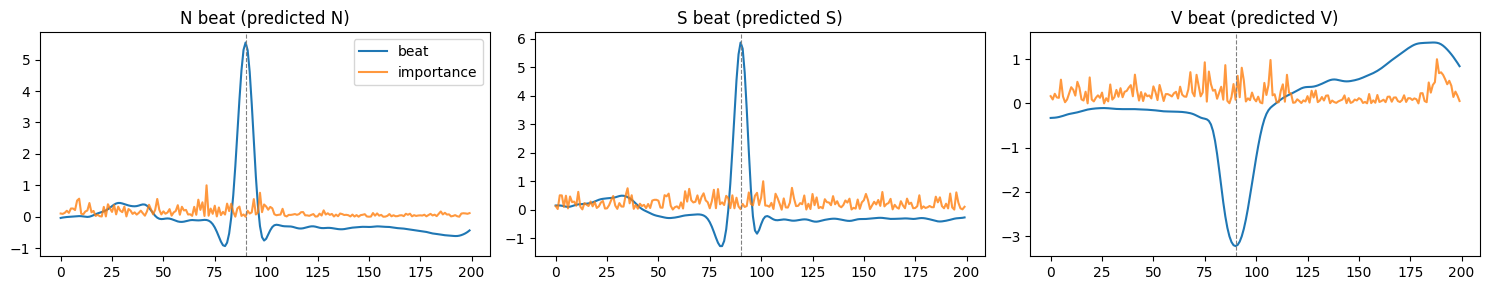

In [26]:
def saliency(model, beat, feat):
    xb = tf.convert_to_tensor(beat[None, :, None], dtype=tf.float32)
    xf = tf.convert_to_tensor(feat[None, :], dtype=tf.float32)
    with tf.GradientTape() as tape:
        tape.watch(xb)
        out = model([xb, xf], training=False)
        cls = int(tf.argmax(out[0]))
        score = out[0, cls]
    g = tf.abs(tape.gradient(score, xb))[0, :, 0].numpy()
    return g / (g.max() + 1e-8), cls

fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, c in zip(axes, [0, 1, 2]):
    idx = np.where((y_test == c) & (best_p == c))[0][0]     # sahi pakda hua beat
    g, cls = saliency(best_m, X_test[idx], f_test[idx])
    ax.plot(X_test[idx], label='beat')
    ax.plot(g, label='importance', alpha=0.8)
    ax.axvline(90, color='gray', ls='--', lw=0.8)             # R-peak ki position
    ax.set_title(f'{names[c]} beat (predicted {names[cls]})')
axes[0].legend()
plt.tight_layout()
plt.savefig(f'{BASE}/saliency.png', dpi=150); plt.show()

In [27]:
conv = tf.lite.TFLiteConverter.from_keras_model(best_m)
conv.optimizations = [tf.lite.Optimize.DEFAULT]
tfl = conv.convert()
open(f'{BASE}/cnn_rr.tflite', 'wb').write(tfl)

keras_kb = os.path.getsize(f'{BASE}/best_cnn_rr.keras') / 1024
tfl_kb = len(tfl) / 1024
print(f'Keras: {keras_kb:.0f} KB | TFLite: {tfl_kb:.0f} KB | {keras_kb / tfl_kb:.1f}x chhota')

interp = tf.lite.Interpreter(model_content=tfl)
interp.allocate_tensors()
ins = interp.get_input_details()
beat_in = [d for d in ins if d['shape'][1] == 200][0]
feat_in = [d for d in ins if d['shape'][1] == 5][0]
out = interp.get_output_details()[0]

preds, t = [], time.time()
for b, f in zip(X_test, f_test):
    interp.set_tensor(beat_in['index'], b[None, :, None].astype(np.float32))
    interp.set_tensor(feat_in['index'], f[None, :].astype(np.float32))
    interp.invoke()
    preds.append(np.argmax(interp.get_tensor(out['index'])[0]))
ms = (time.time() - t) / len(X_test) * 1000
preds = np.array(preds)

print(f'Latency: {ms:.2f} ms/beat (Colab CPU)')
print('Keras macro-F1 :', round(macro_f1_4(y_test, best_p), 4))
print('TFLite macro-F1:', round(macro_f1_4(y_test, preds), 4))
print('Predictions match:', round((preds == best_p).mean() * 100, 2), '%')

Saved artifact at '/tmp/tmp00qa47qr'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): List[TensorSpec(shape=(None, 200, 1), dtype=tf.float32, name='keras_tensor_87'), TensorSpec(shape=(None, 5), dtype=tf.float32, name='keras_tensor_96')]
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  140287299240400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140287299255952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140287299250768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140287299240784: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140287299249808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140287299240976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140287299250000: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140287299253264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140287299250960: TensorSpec(shape=(), dtype=tf.resource, name=None)
  140287299

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Latency: 0.28 ms/beat (Colab CPU)
Keras macro-F1 : 0.6096
TFLite macro-F1: 0.6091
Predictions match: 99.63 %


normal         : [0.957 0.557 0.918 0.007] | macro-F1 0.6096
RR shuffled    : [0.886 0.082 0.537 0.001] | macro-F1 0.3768
shape shuffled : [0.93  0.315 0.218 0.055] | macro-F1 0.3796


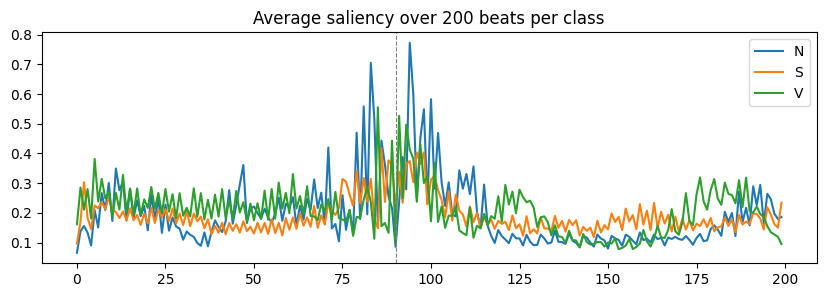

In [28]:
def eval_with(Xb, f):
    p = np.argmax(best_m.predict([Xb[..., None], f], verbose=0), axis=1)
    return f1_score(y_test, p, labels=[0, 1, 2, 3], average=None, zero_division=0)

rng = np.random.default_rng(0)
base = eval_with(X_test, f_test)

f_shuf = f_test.copy(); rng.shuffle(f_shuf)      # timing info tod di
X_shuf = X_test.copy(); rng.shuffle(X_shuf)      # shape info tod di

rr_broken = eval_with(X_test, f_shuf)
shape_broken = eval_with(X_shuf, f_test)

print('normal         :', np.round(base, 3),         '| macro-F1', round(base.mean(), 4))
print('RR shuffled    :', np.round(rr_broken, 3),    '| macro-F1', round(rr_broken.mean(), 4))
print('shape shuffled :', np.round(shape_broken, 3), '| macro-F1', round(shape_broken.mean(), 4))

# average saliency (ek beat ki jagah 200 beats ka average, noise kam hota hai)
def mean_sal(c, n=200):
    idx = np.where((y_test == c) & (best_p == c))[0][:n]
    return np.mean([saliency(best_m, X_test[i], f_test[i])[0] for i in idx], axis=0)

plt.figure(figsize=(10, 3))
for c in [0, 1, 2]:
    plt.plot(mean_sal(c), label=names[c])
plt.axvline(90, color='gray', ls='--', lw=0.8)
plt.legend(); plt.title('Average saliency over 200 beats per class')
plt.savefig(f'{BASE}/saliency_avg.png', dpi=150); plt.show()

In [29]:
!pip install -q gradio
import gradio as gr

CLASSES = ['N (Normal)', 'S (Supraventricular)', 'V (Ventricular)', 'F (Fusion)', 'Q (Unknown)']

def predict(i):
    i = int(i)
    probs = best_m.predict([X_test[i][None, :, None], f_test[i][None, :]], verbose=0)[0]
    fig, ax = plt.subplots(figsize=(7, 2.5))
    ax.plot(X_test[i]); ax.axvline(90, ls='--', c='gray')
    ax.set_title(f'True label: {CLASSES[y_test[i]]}')
    plt.close(fig)
    return fig, {c: float(p) for c, p in zip(CLASSES, probs)}

gr.Interface(predict,
             gr.Slider(0, len(X_test) - 1, step=1, value=0, label='Test beat index'),
             [gr.Plot(), gr.Label(num_top_classes=5)],
             title='ECG Arrhythmia Detection (CNN + RR, MIT-BIH)').launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://50b2979fb079bb3067.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [30]:
print('N examples:', np.where((y_test == 0) & (best_p == 0))[0][:5])
print('S examples:', np.where((y_test == 1) & (best_p == 1))[0][:5])
print('V examples:', np.where((y_test == 2) & (best_p == 2))[0][:5])

N examples: [0 1 2 3 4]
S examples: [  6 229 257 341 440]
V examples: [1905 4376 4385 4403 4436]


In [31]:
print('N ko S bola :', np.where((y_test == 0) & (best_p == 1))[0][:5])
print('S ko N bola :', np.where((y_test == 1) & (best_p == 0))[0][:5])
print('F ke examples:', np.where(y_test == 3)[0][:5])

N ko S bola : [6041 6059 6074 6103 6160]
S ko N bola : [ 3624 16054 16414 16516 16667]
F ke examples: [16639 17338 19699 20529 21289]
